# Animations

`scene.animate(update, frames)` draws the scene, then calls `update(i)` before each further
frame `i`. The update function changes the geometry — here it turns a box a little. All frames
are captured first, so the animation plays smoothly and can loop.

* **plotly** gives a figure with a play button and a slider. It runs in the browser, also in an
  exported HTML file, and the view can be rotated while it plays.
* **matplotlib** plays live with ipympl (`%matplotlib widget`); with the default inline backend,
  Jupyter shows it as an HTML player.
* **raytrace** traces every frame and makes an animated PNG, which plays wherever images are
  shown: in Jupyter, on web pages and in a README.

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/asteppke/minigeo/HEAD?labpath=examples%2Fanimations.ipynb) [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/asteppke/minigeo/blob/main/examples/animations.ipynb)

In [1]:
# On Google Colab, install minigeo first (elsewhere this cell does nothing)
import sys

if "google.colab" in sys.modules:
    %pip install -q "minigeo[all] @ git+https://github.com/asteppke/minigeo" ipympl
    from google.colab import output

    output.enable_custom_widget_manager()

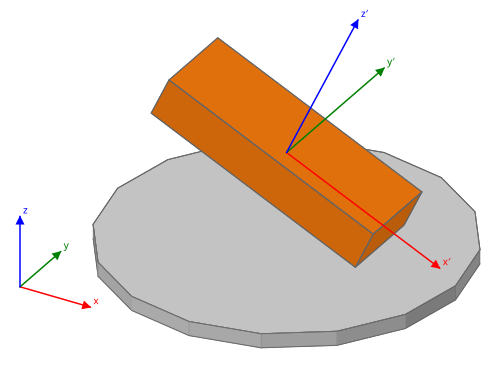

In [2]:
from minigeo import Box, Cylinder, Scene


def turning_box_scene():
    """A box standing on a disc, tilted, turning around its own long axis x'."""
    scene = Scene()
    base = scene.add(Cylinder([0, 0, 0], radius=1.2, height=0.1), fill="lightgray")
    box = Box(base.anchor("top"), size=[1.6, 0.6, 0.3], anchor="bottom")
    box.place("center", at=base.anchor("top") + [0, 0, 0.6])
    box.rotate("y", 25, about="center")
    scene.add(box, fill="C1", frame=True)
    scene.add_frame([-1.2, -1.2, 0], length=0.5)
    return scene, box


scene, box = turning_box_scene()
scene

## With plotly

Each frame turns the box by 10° around its own x' axis; 36 frames make a full turn.
Press ▶ to play. `figure.write_html("turning_box.html")` saves it as a web page.

In [3]:
scene, box = turning_box_scene()
scene.animate(lambda frame: box.rotate("x'", 10, about="center"), frames=36, height=450)

## With matplotlib

With the default inline backend the animation becomes an HTML player: press ▶ to play. All frames
are drawn first, which takes a moment. `animation.save("turning_box.gif")` writes a GIF.

In [4]:
scene, box = turning_box_scene()
scene.animate(
    lambda frame: box.rotate("x'", 10, about="center"), frames=36, backend="matplotlib", interval=60
)

MatplotlibAnimation with 36 frames

## Ray traced

Every frame is ray traced, with light and shadows, and every look works — here `"diagram"`,
with outlines and soft corners. The frames share one view, so the picture does not jump.
`movie.save("turning_box.png")` writes the animated PNG; `.gif` and `.webp` work too. Tracing
takes a moment per frame (much less with the `fast` extra, numba).

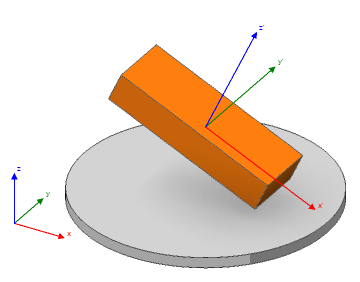

In [5]:
scene, box = turning_box_scene()
movie = scene.animate(
    lambda frame: box.rotate("x'", 10, about="center"),
    frames=36,
    backend="raytrace",
    look="diagram",
    width=360,
)
movie

### Live with ipympl

With `%matplotlib widget` (needs `pip install ipympl`) the animation plays in the live figure, and
the view can be rotated with the mouse while it runs. Keep a reference to the animation (here
`animation`), otherwise Python may stop it.

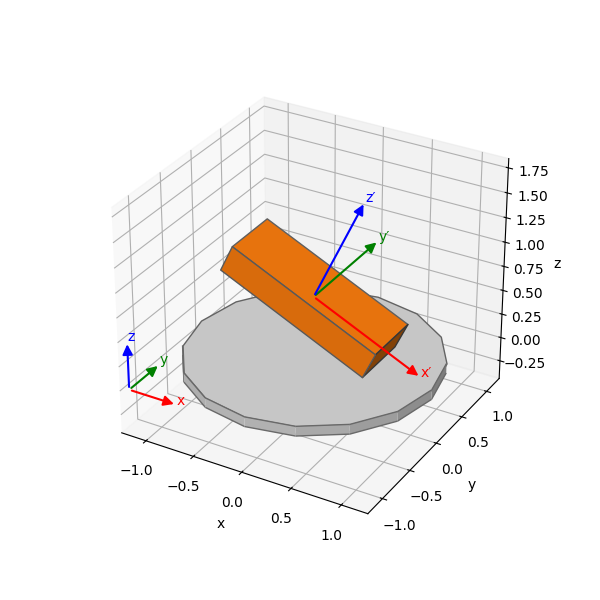

In [6]:
%matplotlib widget
scene, box = turning_box_scene()
animation = scene.animate(
    lambda frame: box.rotate("x'", 10, about="center"), frames=36, backend="matplotlib", interval=60
)